In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
data_dict = {

    "Gene": [
        "Gene1", "Gene2", "Gene3", "Gene4", "Gene5",
        "Gene6", "Gene7", "Gene8", "Gene9", "Gene10"
    ],

    "Control_1": [100, 500, 50, 800, 200, 1000, 75, 450, 300, 150],

    "Control_2": [110, 480, 55, 820, 210, 980, 80, 460, 310, 160],

    "Control_3": [105, 510, 52, 790, 205, 1020, 78, 440, 295, 155],

    "Treatment_1": [250, 200, 60, 400, 600, 990, 300, 100, 700, 500],

    "Treatment_2": [260, 210, 58, 420, 620, 1010, 310, 110, 720, 510],

    "Treatment_3": [245, 190, 62, 410, 610, 1005, 295, 105, 680, 490]
}

# Convert dictionary into DataFrame

data = pd.DataFrame(data_dict)

print(data)

     Gene  Control_1  Control_2  Control_3  Treatment_1  Treatment_2  \
0   Gene1        100        110        105          250          260   
1   Gene2        500        480        510          200          210   
2   Gene3         50         55         52           60           58   
3   Gene4        800        820        790          400          420   
4   Gene5        200        210        205          600          620   
5   Gene6       1000        980       1020          990         1010   
6   Gene7         75         80         78          300          310   
7   Gene8        450        460        440          100          110   
8   Gene9        300        310        295          700          720   
9  Gene10        150        160        155          500          510   

   Treatment_3  
0          245  
1          190  
2           62  
3          410  
4          610  
5         1005  
6          295  
7          105  
8          680  
9          490  


In [11]:
print("RNA-SEQ DATASET INFORMATION")

print("Number of genes:", len(data))

print("Number of samples:", len(data.columns) - 1)

print("\nMissing Values:")

print(data.isnull().sum())

RNA-SEQ DATASET INFORMATION
Number of genes: 10
Number of samples: 6

Missing Values:
Gene           0
Control_1      0
Control_2      0
Control_3      0
Treatment_1    0
Treatment_2    0
Treatment_3    0
dtype: int64


In [12]:
control_samples = [
    "Control_1",
    "Control_2",
    "Control_3"
]

treatment_samples = [
    "Treatment_1",
    "Treatment_2",
    "Treatment_3"
]

print("Control Samples:", control_samples)

print("Treatment Samples:", treatment_samples)

Control Samples: ['Control_1', 'Control_2', 'Control_3']
Treatment Samples: ['Treatment_1', 'Treatment_2', 'Treatment_3']


In [13]:
# Calculate average expression in Control group

data["Control_Mean"] = data[control_samples].mean(axis=1)

# Calculate average expression in Treatment group

data["Treatment_Mean"] = data[treatment_samples].mean(axis=1)


print(data[["Gene", "Control_Mean", "Treatment_Mean"]])

     Gene  Control_Mean  Treatment_Mean
0   Gene1    105.000000      251.666667
1   Gene2    496.666667      200.000000
2   Gene3     52.333333       60.000000
3   Gene4    803.333333      410.000000
4   Gene5    205.000000      610.000000
5   Gene6   1000.000000     1001.666667
6   Gene7     77.666667      301.666667
7   Gene8    450.000000      105.000000
8   Gene9    301.666667      700.000000
9  Gene10    155.000000      500.000000


In [14]:
# Calculate Log2 Fold Change

data["Log2_Fold_Change"] = np.log2(
    (data["Treatment_Mean"] + 1) /
    (data["Control_Mean"] + 1)
)

print(data[["Gene", "Log2_Fold_Change"]])

     Gene  Log2_Fold_Change
0   Gene1          1.253171
1   Gene2         -1.307984
2   Gene3          0.193772
3   Gene4         -0.968655
4   Gene5          1.568528
5   Gene6          0.002400
6   Gene7          1.943905
7   Gene8         -2.089063
8   Gene9          1.211685
9  Gene10          1.683265


In [15]:
p_values = []

# Perform t-test for every gene

for index, row in data.iterrows():

    control_values = row[control_samples].astype(float)

    treatment_values = row[treatment_samples].astype(float)

    statistic, p_value = ttest_ind(
        treatment_values,
        control_values,
        equal_var=False
    )

    p_values.append(p_value)


# Add p-values to dataset

data["P_Value"] = p_values

print(data[["Gene", "P_Value"]])

     Gene   P_Value
0   Gene1  0.000035
1   Gene2  0.000034
2   Gene3  0.016036
3   Gene4  0.000013
4   Gene5  0.000011
5   Gene6  0.906197
6   Gene7  0.000111
7   Gene8  0.000017
8   Gene9  0.000201
9  Gene10  0.000017


In [16]:
# Apply Benjamini-Hochberg correction

adjusted_values = multipletests(
    data["P_Value"],
    method="fdr_bh"
)[1]


# Add adjusted p-values to dataset

data["Adjusted_P_Value"] = adjusted_values

print(data[["Gene", "P_Value", "Adjusted_P_Value"]])

     Gene   P_Value  Adjusted_P_Value
0   Gene1  0.000035          0.000058
1   Gene2  0.000034          0.000058
2   Gene3  0.016036          0.017818
3   Gene4  0.000013          0.000043
4   Gene5  0.000011          0.000043
5   Gene6  0.906197          0.906197
6   Gene7  0.000111          0.000158
7   Gene8  0.000017          0.000043
8   Gene9  0.000201          0.000252
9  Gene10  0.000017          0.000043


In [17]:
# Set thresholds

p_value_threshold = 0.05

log2_fc_threshold = 1


# Identify upregulated genes

upregulated = data[
    (data["Adjusted_P_Value"] < p_value_threshold) &
    (data["Log2_Fold_Change"] >= log2_fc_threshold)
]


# Identify downregulated genes

downregulated = data[
    (data["Adjusted_P_Value"] < p_value_threshold) &
    (data["Log2_Fold_Change"] <= -log2_fc_threshold)
]


print("Upregulated Genes:", len(upregulated))

print("Downregulated Genes:", len(downregulated))

Upregulated Genes: 5
Downregulated Genes: 2


In [18]:
result_columns = [
    "Gene",
    "Control_Mean",
    "Treatment_Mean",
    "Log2_Fold_Change",
    "P_Value",
    "Adjusted_P_Value"
]


print("UPREGULATED GENES")

print(upregulated[result_columns])


print("\nDOWNREGULATED GENES")

print(downregulated[result_columns])

UPREGULATED GENES
     Gene  Control_Mean  Treatment_Mean  Log2_Fold_Change   P_Value  \
0   Gene1    105.000000      251.666667          1.253171  0.000035   
4   Gene5    205.000000      610.000000          1.568528  0.000011   
6   Gene7     77.666667      301.666667          1.943905  0.000111   
8   Gene9    301.666667      700.000000          1.211685  0.000201   
9  Gene10    155.000000      500.000000          1.683265  0.000017   

   Adjusted_P_Value  
0          0.000058  
4          0.000043  
6          0.000158  
8          0.000252  
9          0.000043  

DOWNREGULATED GENES
    Gene  Control_Mean  Treatment_Mean  Log2_Fold_Change   P_Value  \
1  Gene2    496.666667           200.0         -1.307984  0.000034   
7  Gene8    450.000000           105.0         -2.089063  0.000017   

   Adjusted_P_Value  
1          0.000058  
7          0.000043  


In [19]:
print("COMPLETE DIFFERENTIAL EXPRESSION RESULTS")

print(data[result_columns].to_string(index=False))

COMPLETE DIFFERENTIAL EXPRESSION RESULTS
  Gene  Control_Mean  Treatment_Mean  Log2_Fold_Change  P_Value  Adjusted_P_Value
 Gene1    105.000000      251.666667          1.253171 0.000035          0.000058
 Gene2    496.666667      200.000000         -1.307984 0.000034          0.000058
 Gene3     52.333333       60.000000          0.193772 0.016036          0.017818
 Gene4    803.333333      410.000000         -0.968655 0.000013          0.000043
 Gene5    205.000000      610.000000          1.568528 0.000011          0.000043
 Gene6   1000.000000     1001.666667          0.002400 0.906197          0.906197
 Gene7     77.666667      301.666667          1.943905 0.000111          0.000158
 Gene8    450.000000      105.000000         -2.089063 0.000017          0.000043
 Gene9    301.666667      700.000000          1.211685 0.000201          0.000252
Gene10    155.000000      500.000000          1.683265 0.000017          0.000043


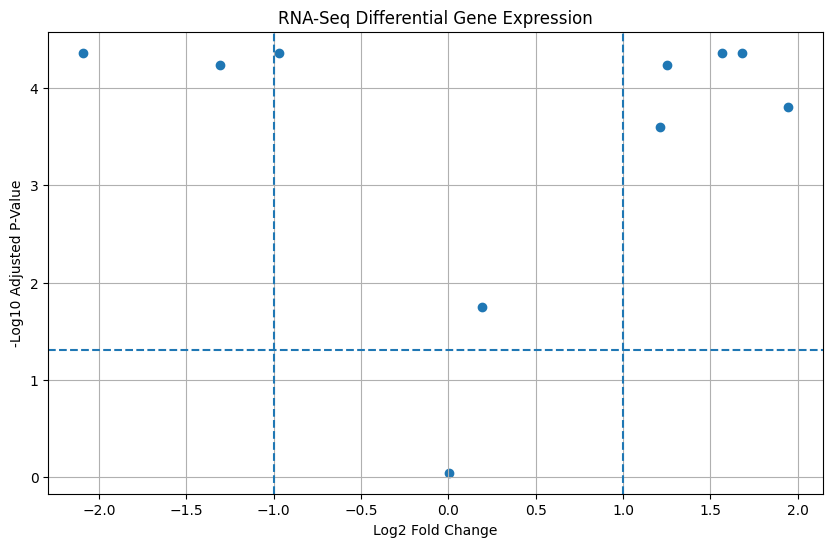

In [20]:
# Calculate negative log10 of adjusted p-value

data["Negative_Log10_P"] = -np.log10(
    data["Adjusted_P_Value"].clip(lower=1e-300)
)


# Create volcano plot

plt.figure(figsize=(10, 6))

plt.scatter(
    data["Log2_Fold_Change"],
    data["Negative_Log10_P"]
)


# Add threshold lines

plt.axvline(x=1, linestyle="--")

plt.axvline(x=-1, linestyle="--")

plt.axhline(
    y=-np.log10(0.05),
    linestyle="--"
)


# Add labels and title

plt.xlabel("Log2 Fold Change")

plt.ylabel("-Log10 Adjusted P-Value")

plt.title("RNA-Seq Differential Gene Expression")

plt.grid(True)

plt.show()

In [21]:
# Save results into CSV file

data.to_csv(
    "differential_expression_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
